In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime

## 1.Data Collection

In [108]:
now = datetime.now()
start = datetime(now.year-10,now.month,now.day)
end = now
ticker ='AAPL'
df = yf.download(ticker,start,end)
df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600
2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000
2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400
2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200
2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800
...,...,...,...,...,...
2026-10-12,340.970001,342.630005,337.600006,338.220001,25900600
2026-10-13,341.269989,348.149994,340.739990,344.670013,38983800


## 2. Data Exploration and Visualisation

In [109]:
type(df)

pandas.DataFrame

In [110]:
df.shape

(2514, 5)

In [111]:
df.isna().sum()

Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64

In [112]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,2514.000000,2514.000000,2514.000000,2514.000000,2.514000e+03
mean,135.275053,136.630815,133.785950,135.140347,9.289676e+07
std,82.662118,83.467309,81.775569,82.565065,5.352733e+07
min,24.298477,24.751297,23.923806,24.496153,1.791060e+07
25%,48.873363,49.340150,48.531539,48.778139,5.427825e+07
50%,139.342270,140.815404,137.555618,139.228095,8.080520e+07
75%,189.879494,191.475729,188.468364,189.681061,1.133011e+08
max,343.459991,348.149994,341.720001,346.950012,4.479400e+08


In [113]:
df.dtypes

Price   Ticker
Close   AAPL      float64
High    AAPL      float64
Low     AAPL      float64
Open    AAPL      float64
Volume  AAPL        int64
dtype: object

In [114]:
df.columns

MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

In [115]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600
2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000
2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400
2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200
2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800


In [116]:
df.columns = df.columns.droplevel(1)

In [117]:
df.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='str', name='Price')

In [118]:
df.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600
2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000
2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400
2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200
2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800


In [119]:
df.columns.name = None

In [120]:
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600
2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000
2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400
2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200
2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800


In [121]:
df = df.reset_index()

In [122]:
df.head()

,Date,Close,High,Low,Open,Volume
0,2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600
1,2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000
2,2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400
3,2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200
4,2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800


Text(0, 0.5, 'Close Prices')

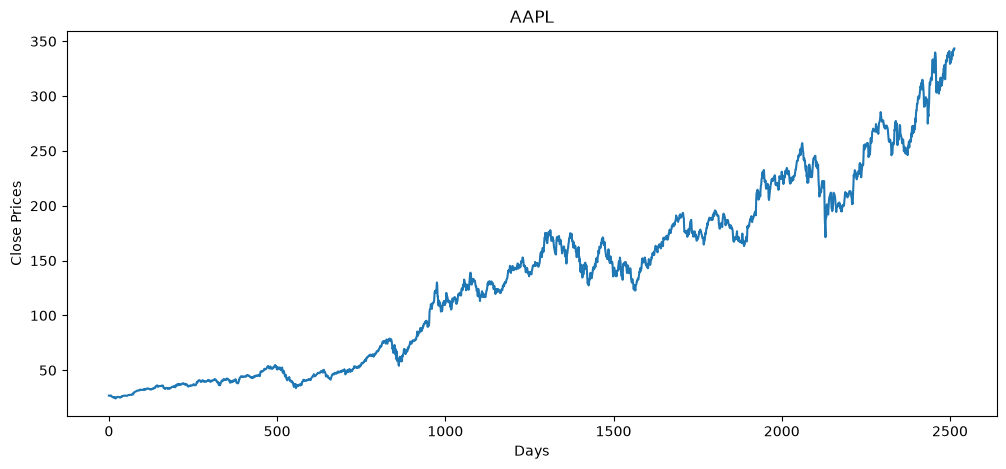

In [123]:
plt.figure(figsize=(12,5))
plt.plot(df.Close)
plt.title(ticker)
plt.xlabel('Days')
plt.ylabel('Close Prices')

## 3.Feature Engineering

In [124]:
df1=pd.DataFrame([10,20,30,40,50,60,70,80,90,100])
df1

,0
0,10
1,20
2,30
3,40
4,50
5,60
6,70
7,80
8,90
9,100


In [125]:
df1['MA_5'] = df1.rolling(5).mean()
df1

,0,MA_5
0,10,NaN
1,20,NaN
2,30,NaN
3,40,NaN
4,50,30.0
5,60,40.0
6,70,50.0
7,80,60.0
8,90,70.0
9,100,80.0


 ## 100 days moving average

In [126]:
df['MA_100'] = df.Close.rolling(100).mean()
df.head(103)

,Date,Close,High,Low,Open,Volume,MA_100
0,2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600,NaN
1,2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000,NaN
2,2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400,NaN
3,2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200,NaN
4,2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800,NaN
...,...,...,...,...,...,...,...
98,2017-03-09,32.015144,32.040539,31.638851,32.028999,88623600,NaN
99,2017-03-10,32.121346,32.172134,32.005917,32.146740,78451200,27.684977
100,2017-03-13,32.135189,32.188285,32.047466,32.054391,69686800,27.737509
101,2017-03-14,32.086727,32.239090,32.052097,32.158292,61236400,27.789739


Text(0, 0.5, 'Prices')

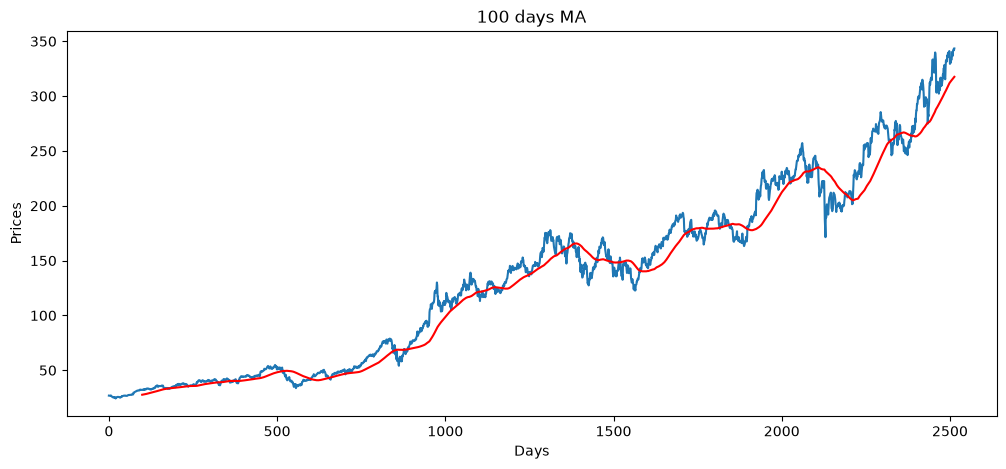

In [127]:
plt.figure(figsize=(12,5))
plt.plot(df.Close)
plt.plot(df['MA_100'],'r')
plt.title('100 days MA')
plt.xlabel('Days')
plt.ylabel('Prices')

 ## 200 days moving average

In [128]:
df['MA_200'] = df.Close.rolling(200).mean()
df.head(203)

,Date,Close,High,Low,Open,Volume,MA_100,MA_200
0,2016-10-17,26.882000,26.948317,26.705911,26.831689,94499600,NaN,NaN
1,2016-10-18,26.863701,27.032928,26.859126,27.026067,98214000,NaN,NaN
2,2016-10-19,26.783665,26.930023,26.024428,26.813393,80138400,NaN,NaN
3,2016-10-20,26.769938,26.843117,26.602998,26.724201,96503200,NaN,NaN
4,2016-10-21,26.664747,26.735641,26.591568,26.712771,92770800,NaN,NaN
...,...,...,...,...,...,...,...,...
198,2017-08-01,34.782982,34.822389,34.402815,34.562764,141474400,33.997056,NaN
199,2017-08-02,36.426510,37.031532,36.199338,36.922582,279747200,34.040108,30.862542
200,2017-08-03,36.062565,36.442732,35.935069,36.405642,108389200,34.079382,30.908445
201,2017-08-04,36.252640,36.486766,36.090374,36.178463,82239600,34.121041,30.955390


Text(0, 0.5, 'Prices')

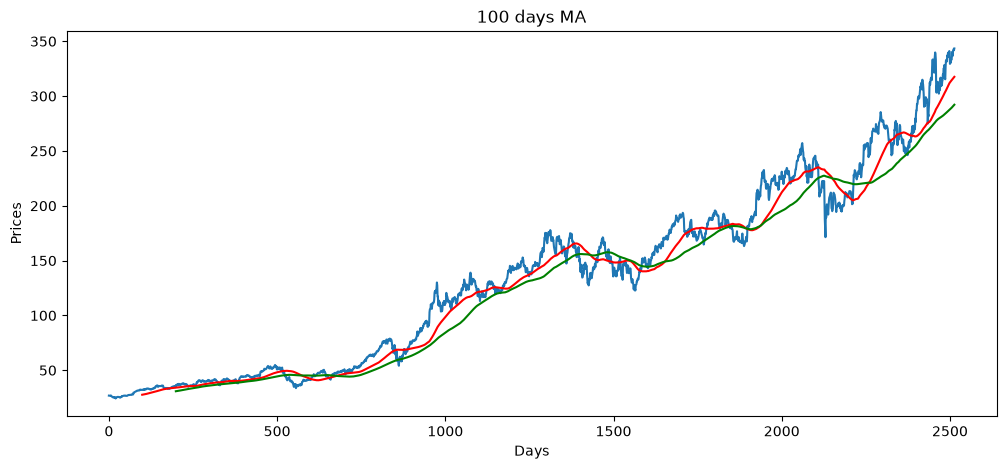

In [129]:
plt.figure(figsize=(12,5))
plt.plot(df.Close)
plt.plot(df['MA_100'],'r')
plt.plot(df['MA_200'],'g')
plt.title('100 days MA')
plt.xlabel('Days')
plt.ylabel('Prices')

## Claculating % change in each trading session

In [130]:
df['Percentage Changed'] = df.Close.pct_change()
df[['Close','Percentage Changed']]

,Close,Percentage Changed
0,26.882000,NaN
1,26.863701,-0.000681
2,26.783665,-0.002979
3,26.769938,-0.000513
4,26.664747,-0.003929
...,...,...
2509,340.970001,0.012862
2510,341.269989,0.000880
2511,342.959991,0.004952
2512,342.000000,-0.002799


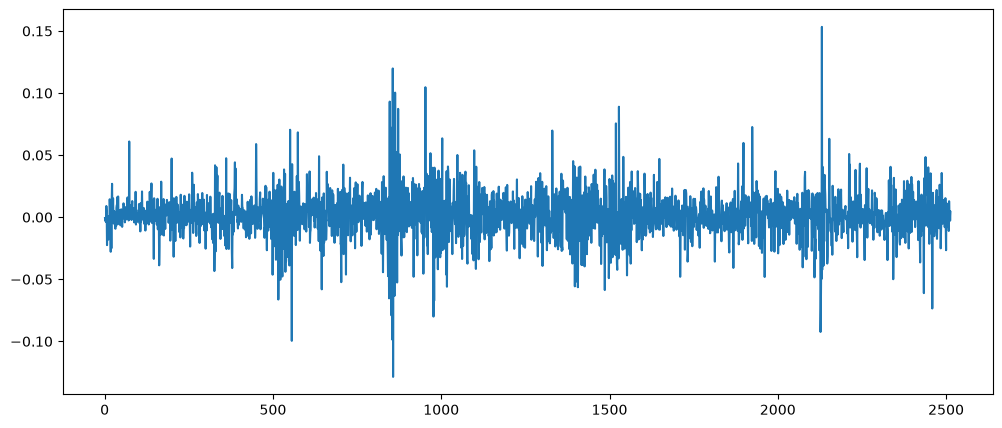

In [131]:
plt.figure(figsize=(12,5))
plt.plot(df['Percentage Changed'])

## 4.Data Preprocessing

In [132]:
df.shape

(2514, 9)

In [133]:
# splitting data into training and testing
df_training = pd.DataFrame(df.Close[0:int(len(df)*0.7)])
df_testing =  pd.DataFrame(df.Close[int(len(df)*0.7):len(df)])

df_testing

,Close
1759,176.463333
1760,176.335052
1761,174.785995
1762,173.493484
1763,173.118561
...,...
2509,340.970001
2510,341.269989
2511,342.959991
2512,342.000000


In [134]:
# Scaling down the data between 0 and 1
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [135]:
data_training_array = scaler.fit_transform(df_training)

In [136]:
data_training_array

array([[0.01526286],
       [0.01515475],
       [0.01468192],
       ...,
       [0.89627371],
       [0.90449263],
       [0.90979688]], shape=(1759, 1))

## 5.Sequence creation

In [137]:
x_train =[]
y_train =[]
for i in range(100,data_training_array.shape[0]):
    x_train.append(data_training_array[i-100:i])
    y_train.append(data_training_array[i,0])
x_train,y_train = np.array(x_train),np.array(y_train),

In [138]:
x_train

array([[[0.01526286],
        [0.01515475],
        [0.01468192],
        ...,
        [0.04602485],
        [0.0455883 ],
        [0.04621571]],

       [[0.01515475],
        [0.01468192],
        [0.01460082],
        ...,
        [0.0455883 ],
        [0.04621571],
        [0.0462975 ]],

       [[0.01468192],
        [0.01460082],
        [0.01397938],
        ...,
        [0.04621571],
        [0.0462975 ],
        [0.0460112 ]],

       ...,

       [[0.86169131],
        [0.87542911],
        [0.87606942],
        ...,
        [0.87598901],
        [0.89102752],
        [0.89977117]],

       [[0.87542911],
        [0.87606942],
        [0.87048121],
        ...,
        [0.89102752],
        [0.89977117],
        [0.89627371]],

       [[0.87606942],
        [0.87048121],
        [0.85511358],
        ...,
        [0.89977117],
        [0.89627371],
        [0.90449263]]], shape=(1659, 100, 1))

## Model Building

In [139]:
!pip install tensorflow

In [140]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


In [141]:
# Ml Model
from keras.models import Sequential
from keras.layers import Dense,LSTM,Input

In [142]:
model =Sequential()
model.add(Input(shape=(100,1)))
model.add(LSTM(units=128,activation='tanh',return_sequences=True))
model.add(LSTM(units=64))
model.add(Dense(25))
model.add(Dense(1))

## Model Training

In [143]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(x_train,y_train,epochs=50)

Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 16s 207ms/step - loss: 0.0110
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 147ms/step - loss: 6.9492e-04
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 154ms/step - loss: 6.3008e-04
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - loss: 6.1809e-04
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - loss: 6.0607e-04
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 150ms/step - loss: 5.8070e-04
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 150ms/step - loss: 5.7109e-04
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - loss: 5.6204e-04
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - loss: 5.4201e-04
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 150ms/step - loss: 5.1957e-04
Epoch 11/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 153ms/step - loss: 5.0451e-04
Epoch 12/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 152ms/step - loss: 4.9543e-04
Epoch 13/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 150ms/step - loss: 4.8507e-04
Epoch 14/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - loss: 4.7227e-04
Epoc

In [144]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 100, 128)            │          66,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 25)                  │           1,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 352,859 (1.35 MB)

 Trainable params: 117,619 (459.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 235,240 (918.91 KB)

In [145]:
# save the trained model
model.save('stock_prediction_model.keras')

## 8. Preparing the test data

In [146]:
df_testing

,Close
1759,176.463333
1760,176.335052
1761,174.785995
1762,173.493484
1763,173.118561
...,...
2509,340.970001
2510,341.269989
2511,342.959991
2512,342.000000


In [147]:
past_100_days = df_training.tail(100)

In [148]:
final_df = pd.concat([past_100_days,df_testing],ignore_index=True)

In [149]:
final_df

,Close
0,171.643600
1,169.042343
2,169.318222
3,170.451355
4,172.855530
...,...
850,340.970001
851,341.269989
852,342.959991
853,342.000000


In [150]:
input_data =scaler.fit_transform(final_df)
input_data

array([[0.04673223],
       [0.0323    ],
       [0.03383062],
       [0.04011744],
       [0.05345623],
       [0.06367917],
       [0.0634058 ],
       [0.07893132],
       [0.08363274],
       [0.07614352],
       [0.07412052],
       [0.06652191],
       [0.08155539],
       [0.0836876 ],
       [0.09915843],
       [0.09653418],
       [0.10003286],
       [0.11129447],
       [0.1053357 ],
       [0.10582765],
       [0.10008772],
       [0.11670652],
       [0.11495722],
       [0.10724907],
       [0.12250139],
       [0.12900697],
       [0.13086548],
       [0.15480985],
       [0.14655523],
       [0.14037762],
       [0.14300161],
       [0.13682408],
       [0.12550795],
       [0.12261068],
       [0.13184963],
       [0.13605902],
       [0.13687902],
       [0.15491932],
       [0.15349799],
       [0.16098738],
       [0.15021781],
       [0.14371231],
       [0.14814054],
       [0.15289674],
       [0.15770729],
       [0.15070984],
       [0.16497818],
       [0.168

In [151]:
input_data.shape

(855, 1)

In [152]:
x_test =[]
y_test =[]
for i in range(100,input_data.shape[0]):
    x_test.append(input_data[i-100:i])
    y_test.append(input_data[i,0])
    
x_test,y_test = np.array(x_test),np.array(y_test)
    

In [153]:
x_test

array([[[0.04673223],
        [0.0323    ],
        [0.03383062],
        ...,
        [0.0709548 ],
        [0.07867345],
        [0.08365484]],

       [[0.0323    ],
        [0.03383062],
        [0.04011744],
        ...,
        [0.07867345],
        [0.08365484],
        [0.07347296]],

       [[0.03383062],
        [0.04011744],
        [0.05345623],
        ...,
        [0.08365484],
        [0.07347296],
        [0.07276124]],

       ...,

       [[0.78510346],
        [0.80633479],
        [0.80361844],
        ...,
        [0.96216156],
        [0.98618509],
        [0.98784948]],

       [[0.80633479],
        [0.80361844],
        [0.81758793],
        ...,
        [0.98618509],
        [0.98784948],
        [0.99722591]],

       [[0.80361844],
        [0.81758793],
        [0.82678997],
        ...,
        [0.98784948],
        [0.99722591],
        [0.99189971]]], shape=(755, 100, 1))

## 9. Making predictions

In [154]:
y_predicted = model.predict(x_test)

24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step


In [155]:
y_predicted

array([[0.07863656],
       [0.07908492],
       [0.07779659],
       [0.07389761],
       [0.0683354 ],
       [0.06334057],
       [0.05607415],
       [0.05039274],
       [0.04751756],
       [0.04288524],
       [0.03280865],
       [0.02565846],
       [0.02440281],
       [0.02615839],
       [0.03309714],
       [0.04532979],
       [0.05451033],
       [0.0639724 ],
       [0.07488309],
       [0.08475848],
       [0.09053886],
       [0.10028832],
       [0.10562567],
       [0.11246902],
       [0.11865105],
       [0.12568915],
       [0.13077652],
       [0.13682199],
       [0.13981944],
       [0.14222305],
       [0.14134833],
       [0.13957895],
       [0.13924518],
       [0.13767625],
       [0.13735044],
       [0.13979232],
       [0.13910556],
       [0.14483386],
       [0.14859325],
       [0.15410516],
       [0.16090485],
       [0.16119112],
       [0.162364  ],
       [0.169297  ],
       [0.17580801],
       [0.1790459 ],
       [0.17716686],
       [0.176

In [156]:
y_test

array([0.07347296, 0.07276124, 0.0641668 , 0.05699572, 0.05491558,
       0.04079226, 0.04144921, 0.04385783, 0.03104832, 0.008002  ,
       0.01528288, 0.02661425, 0.0292418 , 0.0467589 , 0.06646587,
       0.06142971, 0.07555294, 0.08973095, 0.09558846, 0.09296075,
       0.11614684, 0.10737665, 0.12184757, 0.12497189, 0.13429034,
       0.13418045, 0.14382779, 0.13938779, 0.14306044, 0.13571539,
       0.1347287 , 0.13807237, 0.13242641, 0.13560567, 0.14267669,
       0.13275531, 0.15462598, 0.14859652, 0.15928524, 0.16717837,
       0.15331047, 0.16169707, 0.17951133, 0.18033353, 0.1773737 ,
       0.16816498, 0.17392032, 0.16235479, 0.1615325 , 0.15561267,
       0.1525979 , 0.15314598, 0.15550304, 0.14974762, 0.11198105,
       0.10436196, 0.09153544, 0.08753406, 0.11154261, 0.10924049,
       0.11499591, 0.11170701, 0.11351591, 0.10096351, 0.09575617,
       0.12837034, 0.14443064, 0.1572023 , 0.16427315, 0.16054589,
       0.15873682, 0.14914459, 0.14536256, 0.1251363 , 0.10518

In [157]:
y_predicted = scaler.inverse_transform(y_predicted.reshape(-1,1)).flatten()
y_test = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

In [158]:
y_predicted

array([177.39401, 177.47482, 177.24263, 176.53987, 175.53734, 174.63707,
       173.32738, 172.30336, 171.78514, 170.95023, 169.13402, 167.84528,
       167.61896, 167.9354 , 169.18602, 171.39082, 173.04552, 174.75095,
       176.71748, 178.49742, 179.53929, 181.29652, 182.25853, 183.49196,
       184.6062 , 185.87474, 186.79169, 187.88132, 188.42159, 188.85481,
       188.69714, 188.37822, 188.31808, 188.03528, 187.97656, 188.41669,
       188.29291, 189.32538, 190.00298, 190.99643, 192.222  , 192.27359,
       192.485  , 193.73459, 194.90814, 195.49173, 195.15306, 195.03322,
       194.30519, 193.62294, 192.83331, 192.11105, 191.689  , 191.63702,
       191.3721 , 188.94568, 186.31201, 183.74571, 181.78346, 181.88705,
       182.46577, 183.33258, 183.83206, 184.15361, 183.61008, 182.6836 ,
       183.70929, 185.91344, 188.53276, 190.8575 , 192.1029 , 192.5062 ,
       191.95299, 191.0951 , 189.26083, 186.64801, 185.42671, 184.68446,
       184.89172, 185.82758, 186.729  , 186.99255, 

In [159]:
y_test

array([176.46333313, 176.33505249, 174.78599548, 173.4934845 ,
       173.11856079, 170.57298279, 170.69139099, 171.1255188 ,
       168.81674194, 164.66288757, 165.97518921, 168.01754761,
       168.49113464, 171.64840698, 175.20037842, 174.29266357,
       176.83822632, 179.3936615 , 180.44941711, 179.97579956,
       184.15484619, 182.57411194, 185.18234253, 185.74546814,
       187.42501831, 187.4052124 , 189.14404297, 188.34378052,
       189.0057373 , 187.68186951, 187.50402832, 188.10668945,
       187.08906555, 187.66209412, 188.93656921, 187.14834595,
       191.09030151, 190.0035553 , 191.93008423, 193.35273743,
       190.85319519, 192.36479187, 195.57562256, 195.72381592,
       195.19033813, 193.53056335, 194.56790161, 192.4833374 ,
       192.33512878, 191.2681427 , 190.72476196, 190.82354736,
       191.24838257, 190.21102905, 183.40400696, 182.03074646,
       179.71890259, 178.99769592, 183.32498169, 182.91004944,
       183.94740295, 183.35461426, 183.6806488 , 181.41

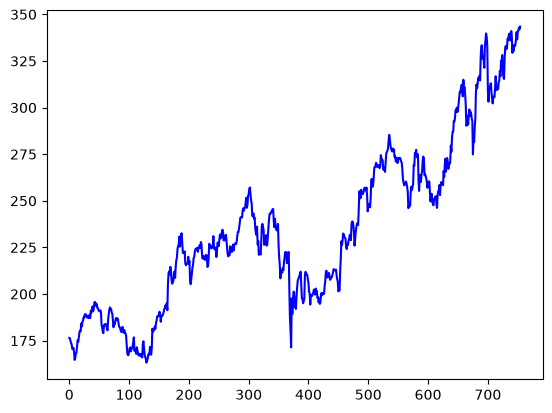

In [160]:
plt.plot(y_test,'b',label='original_price')

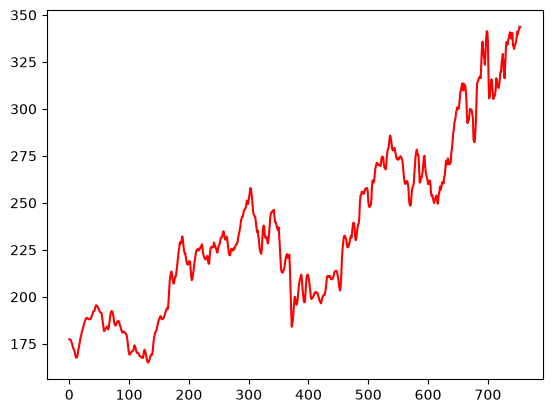

In [161]:
plt.plot(y_predicted,'r',label='predicted_price')

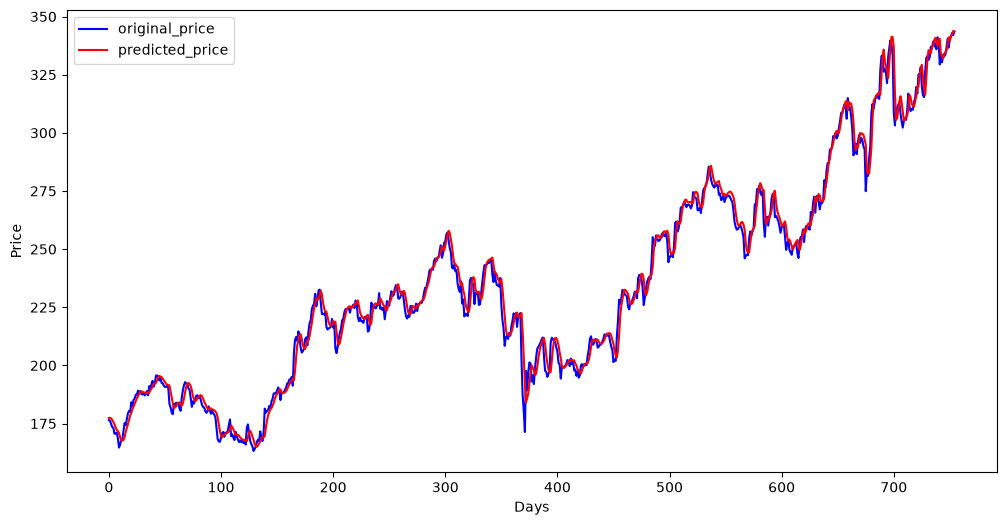

In [162]:
plt.figure(figsize=(12,6))
plt.plot(y_test,'b',label='original_price')
plt.plot(y_predicted,'r',label='predicted_price')
plt.xlabel('Days')
plt.ylabel('Price')
plt.legend()

(200.0, 320.0)

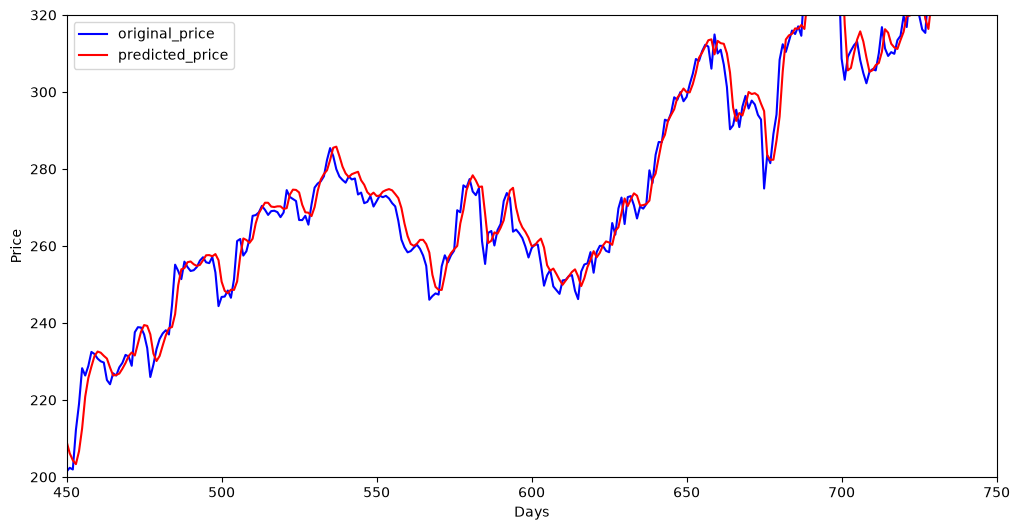

In [166]:
plt.figure(figsize=(12,6))
plt.plot(y_test,'b',label='original_price')
plt.plot(y_predicted,'r',label='predicted_price')
plt.xlabel('Days')
plt.ylabel('Price')
plt.legend()
plt.xlim(450,750)
plt.ylim(200,320)

## Model Evaluation

In [172]:
# Mean Squared Error
from sklearn.metrics import mean_squared_error, r2_score


In [168]:
mse = mean_squared_error(y_test,y_predicted)
print(f"Mean Squared Error (MSE):{mse}")

Mean Squared Error (MSE):22.87338151333773


In [169]:
# Root Mean Squared Error

In [170]:
rmse = np.sqrt(mse)
print(f" Root Mean Squared Error (RMSE):{rmse}")

 Root Mean Squared Error (RMSE):4.78261241512813


In [173]:
# R-Squared
r2 = r2_score(y_test,y_predicted)
print(f"R-Squared :{r2}")

R-Squared :0.9888098882601504
